In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [4]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda")

BATCH_SIZE = 64
LEARNING_RATE = 1e-3
NUM_EPOCHS = 50
HIDDEN_SIZE = 64

In [13]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Max value: 5.00001
Capped rows: 965 (4.7%)


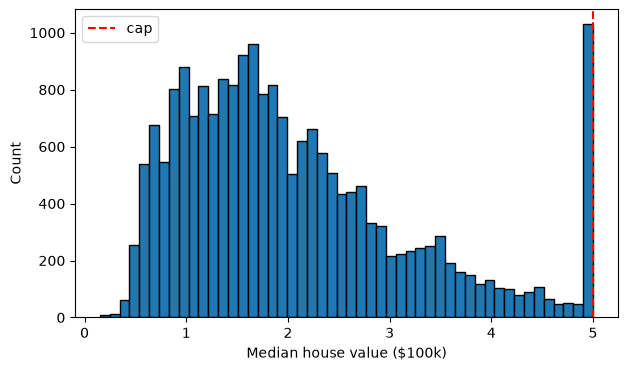

In [14]:
target = df["MedHouseVal"]
is_capped = target == target.max()
print(f"Max value: {target.max()}")
print(f"Capped rows: {is_capped.sum()} ({is_capped.mean():.1%})")

plt.figure(figsize=(7, 4))
plt.hist(target, bins=50, edgecolor="black")
plt.axvline(target.max(), color="red", linestyle="--", label="cap")
plt.xlabel("Median house value ($100k)")
plt.ylabel("Count")
plt.legend()
plt.show()
